***Cell 1: Dataset from Google Drive (zip)***

In [1]:
from google.colab import drive, files
drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/Plant Disease.zip" -d /content/PlantVillage
!ls /content/PlantVillage

Mounted at /content/drive
plantvillage  PlantVillage


***Cell 2: Imports, settings, and feature function***

In [2]:
import os, cv2, time, json, joblib, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

BASE = None
for root, dirs, _ in os.walk("/content/PlantVillage"):
    if any(d.lower().startswith(("potato", "tomato", "pepper")) for d in dirs):
        BASE = root; break
ALL_CLASSES = sorted(c for c in os.listdir(BASE)
                     if c.lower().startswith(("potato", "tomato", "pepper")))
CLASSES = [c for c in ALL_CLASSES if c.lower().startswith("potato")]  # fair comparison = Potato only
print("BASE:", BASE)
print("ALL_CLASSES:", len(ALL_CLASSES))
print("CLASSES (Potato):", CLASSES)

N = 100   # images per class (the quantum models must use the same data)

def features(img):
    img = cv2.resize(img, (64, 64))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h = hog(gray, pixels_per_cell=(16, 16))
    hist = cv2.calcHist([img], [0, 1, 2], None, [4, 4, 4], [0, 256] * 3).flatten()
    return np.concatenate([h, hist])

BASE: /content/PlantVillage/PlantVillage
ALL_CLASSES: 15
CLASSES (Potato): ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


***Cell 3: Explore the dataset***

Potato___Early_blight 1000
Potato___Late_blight 1000
Potato___healthy 152


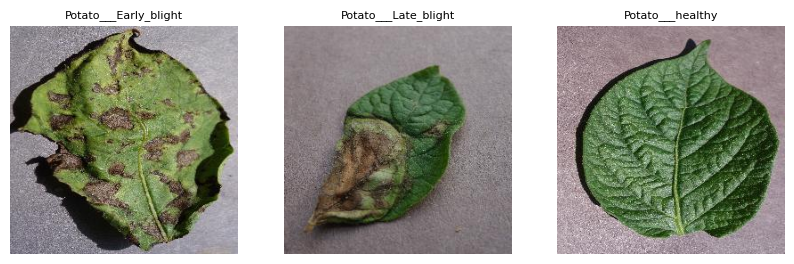

In [3]:
for c in CLASSES:
    print(c, len(os.listdir(os.path.join(BASE, c))))

fig, ax = plt.subplots(1, len(CLASSES), figsize=(10, 3))
for i, c in enumerate(CLASSES):
    f = sorted(os.listdir(os.path.join(BASE, c)))[0]
    img = cv2.imread(os.path.join(BASE, c, f))
    ax[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[i].set_title(c, fontsize=8); ax[i].axis("off")
plt.show()

***Cell 4: Dataset cleaning (corrupted and duplicate images)***

In [4]:
def clean_class(folder):
    seen, good = set(), []
    for f in sorted(os.listdir(folder)):
        p = os.path.join(folder, f)
        img = cv2.imread(p)
        if img is None: continue                     # corrupted image
        h = hashlib.md5(img.tobytes()).hexdigest()
        if h in seen: continue                       # duplicate image
        seen.add(h); good.append(p)
    return good

paths = {c: clean_class(os.path.join(BASE, c)) for c in CLASSES}
for c in CLASSES: print(c, "clean images:", len(paths[c]))

Potato___Early_blight clean images: 1000
Potato___Late_blight clean images: 1000
Potato___healthy clean images: 152


***Cell 5: Train/test split, augmentation, and feature extraction***

In [5]:
all_p, all_y = [], []
for label, c in enumerate(CLASSES):
    sel = paths[c][:N]
    all_p += sel; all_y += [label] * len(sel)

ptr, pte, ytr, yte = train_test_split(all_p, all_y, test_size=0.2,
                                      random_state=42, stratify=all_y)

def extract(plist, augment=False):
    X = []
    for p in plist:
        img = cv2.imread(p)
        X.append(features(img))
        if augment: X.append(features(cv2.flip(img, 1)))   # horizontal flip
    return np.array(X)

Xtr = extract(ptr, augment=True); ytr = np.repeat(ytr, 2)
Xte = extract(pte);               yte = np.array(yte)
print("Train:", Xtr.shape, "Test:", Xte.shape)

Train: (480, 388) Test: (60, 388)


***Cell 6: Scaling and PCA (4 features)***



In [6]:
scaler = StandardScaler().fit(Xtr)
pca = PCA(n_components=4).fit(scaler.transform(Xtr))
print("Variance kept:", pca.explained_variance_ratio_.sum())
Xtr = pca.transform(scaler.transform(Xtr))
Xte = pca.transform(scaler.transform(Xte))

Variance kept: 0.30299651214483525


***Cell 7: Hyperparameter tuning and cross-validation***

In [7]:
grids = {
  "SVM": (SVC(), {"C": [0.1, 1, 10], "kernel": ["rbf", "linear"]}),
  "RandomForest": (RandomForestClassifier(random_state=42),
                   {"n_estimators": [100, 200], "max_depth": [None, 5, 10]}),
  "MLP": (MLPClassifier(max_iter=1000, random_state=42),
          {"hidden_layer_sizes": [(32,), (32, 16)], "alpha": [0.0001, 0.01]}),
}
best = {}
for name, (m, g) in grids.items():
    gs = GridSearchCV(m, g, cv=5, scoring="f1_macro", n_jobs=-1).fit(Xtr, ytr)
    best[name] = gs.best_estimator_
    print(name, gs.best_params_, "CV F1:", round(gs.best_score_, 3))

SVM {'C': 1, 'kernel': 'rbf'} CV F1: 0.71
RandomForest {'max_depth': 5, 'n_estimators': 200} CV F1: 0.672
MLP {'alpha': 0.0001, 'hidden_layer_sizes': (32,)} CV F1: 0.656


***Cell 8: Final evaluation and save models***

===== SVM
                       precision    recall  f1-score   support

Potato___Early_blight       0.67      0.80      0.73        20
 Potato___Late_blight       0.50      0.40      0.44        20
     Potato___healthy       0.55      0.55      0.55        20

             accuracy                           0.58        60
            macro avg       0.57      0.58      0.57        60
         weighted avg       0.57      0.58      0.57        60



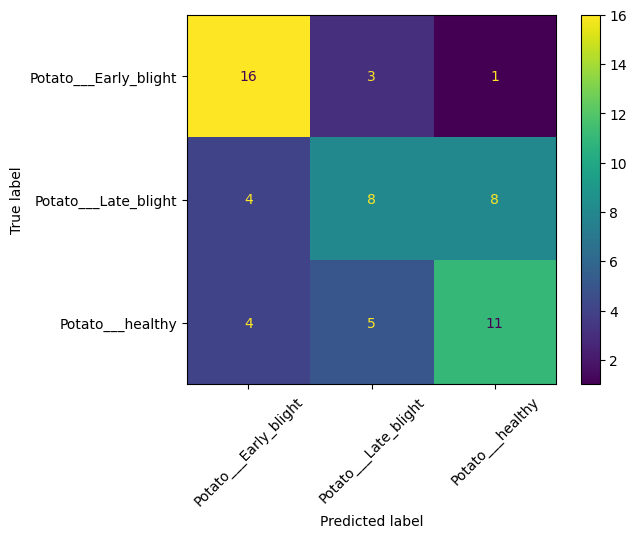

===== RandomForest
                       precision    recall  f1-score   support

Potato___Early_blight       0.64      0.70      0.67        20
 Potato___Late_blight       0.44      0.40      0.42        20
     Potato___healthy       0.50      0.50      0.50        20

             accuracy                           0.53        60
            macro avg       0.53      0.53      0.53        60
         weighted avg       0.53      0.53      0.53        60



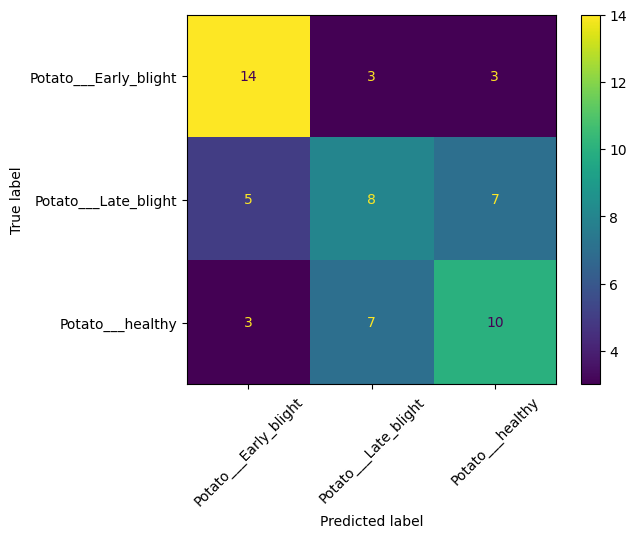

===== MLP
                       precision    recall  f1-score   support

Potato___Early_blight       0.74      0.70      0.72        20
 Potato___Late_blight       0.50      0.45      0.47        20
     Potato___healthy       0.48      0.55      0.51        20

             accuracy                           0.57        60
            macro avg       0.57      0.57      0.57        60
         weighted avg       0.57      0.57      0.57        60



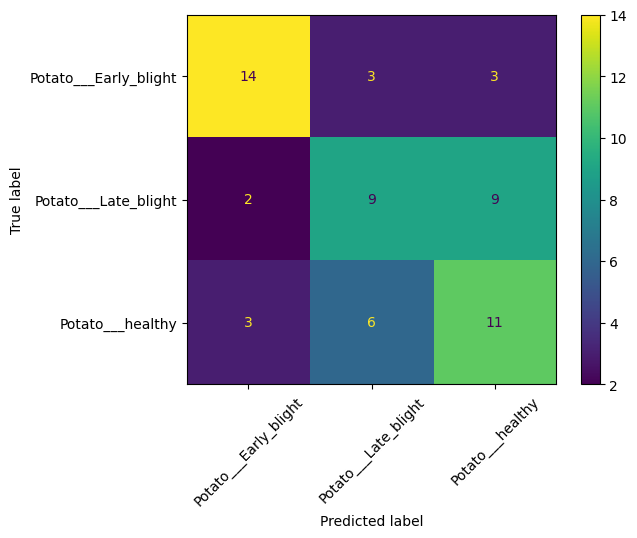

In [8]:
results = {}
for name, m in best.items():
    t = time.time(); m.fit(Xtr, ytr); tt = time.time() - t
    p = m.predict(Xte)
    results[name] = {"accuracy": accuracy_score(yte, p),
                     "precision": precision_score(yte, p, average="macro"),
                     "recall": recall_score(yte, p, average="macro"),
                     "f1": f1_score(yte, p, average="macro"),
                     "train_time": tt}
    print("=====", name)
    print(classification_report(yte, p, target_names=CLASSES))
    ConfusionMatrixDisplay.from_predictions(yte, p, display_labels=CLASSES,
                                            xticks_rotation=45)
    plt.show()
    joblib.dump(m, f"{name}.pkl")

np.savez("split.npz", Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte)
joblib.dump(scaler, "scaler.pkl"); joblib.dump(pca, "pca.pkl")
json.dump(CLASSES, open("classes.json", "w"))
json.dump(results, open("classical_results.json", "w"), indent=2)

***Cell 9: Results table and graph***

              accuracy  precision    recall        f1  train_time
SVM           0.583333   0.572222  0.583333  0.573906    0.030407
RandomForest  0.533333   0.526936  0.533333  0.529240    0.678969
MLP           0.566667   0.571701  0.566667  0.567754    2.175874


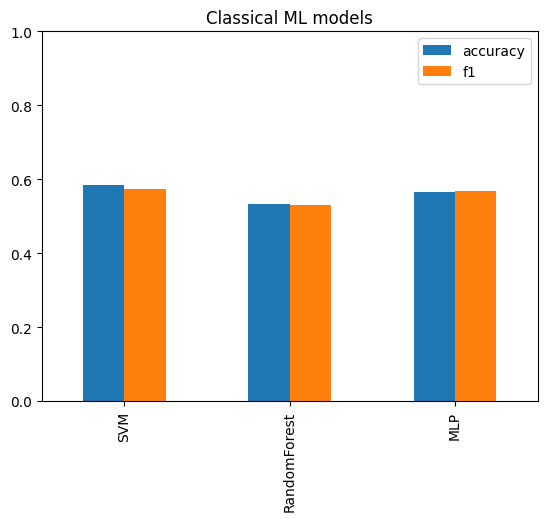

In [9]:
df = pd.DataFrame(results).T
print(df)
df[["accuracy", "f1"]].plot(kind="bar", ylim=(0, 1), title="Classical ML models")
plt.show()

***Cell 10: Download output files (fair comparison)***

In [10]:
!zip -q outputs.zip *.pkl *.npz *.json
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***Cell 11: Website model (all plants, 50 PCA features)***

In [11]:
app_paths = {c: clean_class(os.path.join(BASE, c)) for c in ALL_CLASSES}
APP_CLASSES = ALL_CLASSES
N_APP = min(150, min(len(v) for v in app_paths.values()))
print("Classes:", len(APP_CLASSES), "| images per class:", N_APP)

all_p, all_y = [], []
for label, c in enumerate(APP_CLASSES):
    sel = app_paths[c][:N_APP]; all_p += sel; all_y += [label] * len(sel)

ptr2, pte2, ytr2, yte2 = train_test_split(all_p, all_y, test_size=0.2,
                                          random_state=42, stratify=all_y)
Xtr2 = extract(ptr2, augment=True); ytr2 = np.repeat(ytr2, 2)
Xte2 = extract(pte2);               yte2 = np.array(yte2)

sc2 = StandardScaler().fit(Xtr2)
pca2 = PCA(n_components=50).fit(sc2.transform(Xtr2))
Xtr2 = pca2.transform(sc2.transform(Xtr2))
Xte2 = pca2.transform(sc2.transform(Xte2))

app_models = {
  "SVM": SVC(C=10, probability=True),
  "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
  "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1000, random_state=42),
}
for name, m in app_models.items():
    m.fit(Xtr2, ytr2); p = m.predict(Xte2)
    print(name, "acc:", round(accuracy_score(yte2, p), 3),
          "f1:", round(f1_score(yte2, p, average="macro"), 3))
    joblib.dump(m, f"app_{name}.pkl")
joblib.dump(sc2, "app_scaler.pkl"); joblib.dump(pca2, "app_pca.pkl")
json.dump(APP_CLASSES, open("app_classes.json", "w"))

!zip -q app_models.zip app_*.pkl app_classes.json
files.download("app_models.zip")

Classes: 15 | images per class: 150
SVM acc: 0.64 f1: 0.638
RandomForest acc: 0.56 f1: 0.546
MLP acc: 0.604 f1: 0.602


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***Cell 12: Model Performance data + sample images***

In [12]:
import sklearn, shutil
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import learning_curve
print("scikit-learn version:", sklearn.__version__)

perf = {"classes": APP_CLASSES, "models": {}}
for name, m in app_models.items():
    p = m.predict(Xte2)
    perf["models"][name] = {
        "accuracy": accuracy_score(yte2, p),
        "precision": precision_score(yte2, p, average="macro"),
        "recall": recall_score(yte2, p, average="macro"),
        "f1": f1_score(yte2, p, average="macro"),
        "confusion_matrix": confusion_matrix(yte2, p).tolist()}

sizes, tr, va = learning_curve(app_models["SVM"], Xtr2, ytr2, cv=5,
                               train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
perf["learning_curve"] = {"sizes": sizes.tolist(),
                          "train": tr.mean(axis=1).tolist(),
                          "val": va.mean(axis=1).tolist()}
json.dump(perf, open("model_performance.json", "w"), indent=2)

os.makedirs("samples", exist_ok=True)           # 3 sample images per disease
for c in APP_CLASSES:
    for i, p in enumerate(app_paths[c][:3]):
        shutil.copy(p, f"samples/{c}_{i+1}.jpg")

!zip -qr website_data.zip model_performance.json samples
files.download("website_data.zip")

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>